# `get_trend` 사용법

네이버 쇼핑인사이트에서 키워드 추이를 받아 **DataFrame** 으로 돌려주는 함수 하나짜리 사용 설명서.

코드는 `src/fashion_trend/naver.py` 에 있다. 함수는 두 개뿐이다.

| 함수 | 하는 일 |
|---|---|
| `get_trend(...)` | API 호출 → 긴 형태 DataFrame |
| `to_wide(df)` | 행=날짜, 열=키워드 로 펴기 |

아래 출력은 전부 **실제로 돌려서 받은 값**이다. 날짜가 지나면 숫자는 달라진다.

## 준비

`.env` 에 `NAVER_HUB_KEY_ID` 와 `NAVER_HUB_KEY` 가 들어 있어야 한다.
노트북은 레포 루트에서 연다 (`.env` 를 상대경로로 찾기 때문).

In [1]:
import sys
sys.path.insert(0, "src")

import pandas as pd
from fashion_trend.naver import get_trend, to_wide, plot_trend


## 1. 가장 간단한 사용

키워드 목록만 넘기면 된다. 기본이 최근 52주 주간이라, 예시는 26주로 줄였다.

In [2]:
df = get_trend(["가디건", "니트", "청바지"], weeks=26)

print(df.shape)
df.head()

(81, 4)


,period,keyword,ratio,batch
0,2026-04-20,가디건,57.17073,1
1,2026-04-27,가디건,39.08292,1
2,2026-05-04,가디건,46.04878,1
3,2026-05-11,가디건,32.29268,1
4,2026-05-18,가디건,24.25365,1


In [4]:
df

,period,keyword,ratio,batch
0,2026-04-13,가디건,56.17560,1
1,2026-04-20,가디건,57.17073,1
2,2026-04-27,가디건,39.08292,1
3,2026-05-04,가디건,46.04878,1
4,2026-05-11,가디건,32.29268,1
...,...,...,...,...
76,2026-09-14,청바지,63.16097,1
77,2026-09-21,청바지,49.54146,1
78,2026-09-28,청바지,63.55121,1
79,2026-10-05,청바지,70.47804,1


**이렇게 나온다**

```
(81, 4)

      period keyword     ratio  batch
0 2026-04-13     가디건  56.17560      1
1 2026-04-20     가디건  57.17073      1
2 2026-04-27     가디건  39.08292      1
3 2026-05-04     가디건  46.04878      1
4 2026-05-11     가디건  32.29268      1
```

81행은 키워드 3개 × 27주다. 한 줄에 **키워드 하나의 한 주**가 들어가는 긴 형태다.

## 2. 열 네 개가 뜻하는 것

| 열 | 타입 | 뜻 |
|---|---|---|
| `period` | datetime | 구간 시작일. 주간이면 그 주 월요일 |
| `keyword` | str | 조회한 키워드 |
| `ratio` | float | **상대지수** — 아래 설명 |
| `batch` | int | 몇 번째 요청에서 왔는지 |

`ratio` 가 핵심이다. 절대 클릭수가 아니라 **한 요청 안에서 가장 큰 값을 100으로 둔 비율**이다.
위 출력에서 가디건이 56.17 이라는 건 "이 요청에 담긴 3개 키워드 × 27주 중 최댓값의 56%" 라는 뜻이다.
그래서 숫자 하나만 떼어 보면 의미가 없고, **같은 요청 안의 다른 값과 견줘야** 뜻이 생긴다.

In [ ]:
df.dtypes

```
period     datetime64[us]
keyword               str
ratio             float64
batch               int64
```

`period` 가 문자열이 아니라 datetime 이라 바로 그래프에 올리거나 리샘플링할 수 있다.

## 3. 표로 펴기 — `to_wide`

긴 형태는 다루기 좋지만 눈으로 비교하기 불편하다. `to_wide` 로 돌린다.

In [5]:
wide = to_wide(df)
wide.tail(5).round(2)

keyword,가디건,니트,청바지
period,,,
2026-09-14,100.00,41.42,63.16
2026-09-21,54.85,31.49,49.54
2026-09-28,81.05,49.93,63.55
2026-10-05,73.40,57.11,70.48
2026-10-12,57.99,52.74,63.61


```
keyword        가디건     니트    청바지
period
2026-09-14  100.00  41.42  63.16
2026-09-21   54.85  31.49  49.54
2026-09-28   81.05  49.93  63.55
2026-10-05   73.40  57.11  70.48
2026-10-12   57.99  52.74  63.61
```

9월 14일 가디건이 정확히 `100.00` 인데, 이 요청에서 **그 지점이 최댓값**이었다는 뜻이다.
요청을 바꾸면 100의 자리도 바뀐다.

## 4. 세그먼트 — 전체와 10~20대 여성은 다르다

`gender="f"`, `ages=["10","20"]` 을 주면 그 집단의 추이만 받는다.
에이블리 고객층이 10~20대 여성이므로 이 프로젝트에서는 거의 항상 걸어야 한다.

`ages` 에 들어갈 수 있는 값은 `"10"`, `"20"`, `"30"`, `"40"`, `"50"`, `"60"` 이다.

In [ ]:
seg_all  = get_trend(["가디건"], weeks=26)
seg_1020 = get_trend(["가디건"], weeks=26, gender="f", ages=["10", "20"])

pd.DataFrame({
    "전체":        to_wide(seg_all)["가디건"],
    "10~20대 여성": to_wide(seg_1020)["가디건"],
}).tail(5).round(2)

```
                전체  10~20대 여성
period
2026-09-14  100.00      54.73
2026-09-21   54.85      53.38
2026-09-28   81.05      24.32
2026-10-05   73.40      40.54
2026-10-12   57.99      30.41
```

모양이 꽤 다르다. 9월 28일에 전체는 81로 뛰는데 10~20대 여성은 24로 내려간다.
**전체 트렌드를 보고 사입하면 고객층과 어긋날 수 있다**는 걸 보여주는 숫자다.

다만 두 열은 **서로 다른 요청**에서 왔으므로 절대 크기를 직접 비교하면 안 된다.
각자 자기 요청 안에서 100으로 정규화됐기 때문이다. 비교할 수 있는 건 모양(오르내림)뿐이다.

## 5. 기간과 단위 바꾸기

- `weeks=N` — 최근 N주 (가장 간단)
- `start=`, `end=` — 직접 지정. **2017-08-01 까지 거슬러 올라간다**
- `time_unit` — `"date"`(일) · `"week"`(주) · `"month"`(월)

In [ ]:
monthly = get_trend(["가디건", "니트"],
                    start="2025-01-01", end="2026-10-01",
                    time_unit="month")

to_wide(monthly).head(4).round(1)

```
keyword       가디건    니트
period
2025-01-01   56.6  76.5
2025-02-01   66.5  52.2
2025-03-01  100.0  38.4
2025-04-01   87.2  20.5
```

소급 조회가 된다는 게 중요하다. 새 키워드를 오늘 발견해도 **그 자리에서 과거 패턴을 채울 수 있다**.
1년 기다려 계절성을 확인할 필요가 없다.

## 6. 키워드가 5개를 넘으면  ★ 주의

네이버는 한 요청에 키워드 5개까지만 받는다. 6개를 그냥 넣으면 400 에러가 난다.
`get_trend` 는 알아서 나눠 호출하지만, **나뉜 뒤에는 숫자를 비교할 수 없다.**

In [2]:
big = get_trend(["원피스", "가디건", "니트", "청바지", "셔츠", "코트"], weeks=12)

print(big.groupby("batch")["keyword"].unique())
print()
print("배치별 최댓값")
print(big.groupby("batch")["ratio"].max())

batch
1    [가디건, 니트, 셔츠, 원피스, 청바지]
2                       [코트]
Name: keyword, dtype: object

배치별 최댓값
batch
1    100.0
2    100.0
Name: ratio, dtype: float64


```
batch
1    [가디건, 니트, 셔츠, 원피스, 청바지]
2                       [코트]

배치별 최댓값
batch
1    100.0
2    100.0
```

**두 배치 모두 최댓값이 100이다.** 코트는 혼자 요청됐으니 자기 최고점이 100이 된 것뿐이고,
원피스가 들어간 1번 배치의 100과는 전혀 다른 크기다. 코트가 원피스만큼 팔린다는 뜻이 아니다.

그래서 지금 단계에서는 **키워드를 5개 이하로 끊어 쓰는 게 안전하다.**
더 많이 보려면 모든 배치에 같은 키워드(앵커)를 끼워 넣고 그 값으로 나눠 공통 단위에 올려야 하는데,
그건 아직 구현 안 된 다음 단계다.

## 7. 비어 있는 구간 — `NaN`

작은 키워드는 네이버가 일부 구간을 아예 안 보낸다. 펴면 `NaN` 으로 드러난다.

In [ ]:
small = get_trend(["원피스", "발레코어", "바라클라바"], weeks=26)
w = to_wide(small)

print("결측 구간 수")
print(w.isna().sum())
w.tail(4).round(4)

```
결측 구간 수
바라클라바    18
발레코어       8
원피스        0

keyword      바라클라바    발레코어      원피스
period
2026-09-21  0.0131     NaN  35.8084
2026-09-28  0.0131  0.0175  35.6420
2026-10-05  0.0131  0.0088  30.2176
2026-10-12  0.0131     NaN  24.7712
```

두 가지가 보인다.

**첫째, 결측이 많다.** 바라클라바는 27주 중 18주가 비었다.
검색이 0이었는지, 임계값 아래라 생략된 건지는 응답만으로 구분되지 않는다.

**둘째, 값이 눌려 있다.** 바라클라바가 네 주 내내 `0.0131` 로 똑같다.
변화가 없어서가 아니라 소수점 5자리에서 끊겨 해상도를 잃은 것이다.
원피스가 워낙 커서 작은 키워드가 바닥에 깔리기 때문인데,
**규모가 비슷한 키워드끼리 묶어 조회하면** 완화된다.

## 8. 그래프로

한글 폰트를 먼저 잡아야 글자가 네모로 안 나온다.

<Axes: title={'center': '쇼핑 클릭지수'}, xlabel='period'>

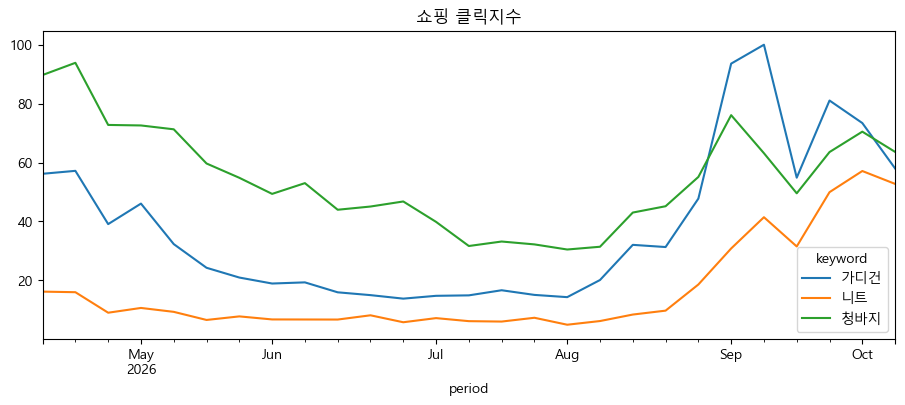

In [6]:
import matplotlib
from matplotlib import font_manager

installed = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "NanumGothic", "AppleGothic", "Gulim"]:
    if name in installed:
        matplotlib.rcParams["font.family"] = name
        break
matplotlib.rcParams["axes.unicode_minus"] = False

wide.plot(figsize=(11, 4), title="쇼핑 클릭지수")

## 9. 파일로 저장

DataFrame 이니 그냥 pandas 로 저장하면 된다.

In [ ]:
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/trend_sample.csv", index=False, encoding="utf-8-sig")

# 다시 읽을 때는 날짜 열을 알려줘야 datetime 으로 돌아온다
back = pd.read_csv("data/raw/trend_sample.csv", parse_dates=["period"])
back.head(3)

`utf-8-sig` 로 쓰면 엑셀에서 열어도 한글이 안 깨진다.

---
## 10. 그래프까지 한 번에 — `plot_trend`

위 8번처럼 폰트 설정하고 `to_wide` 하고 `plot` 하는 걸 한 함수로 묶은 것이다.
**인자는 `get_trend` 와 똑같고**, 그래프용 몇 개가 더 있다.

한글 폰트를 함수 안에서 알아서 잡으니 설정 셀을 따로 돌리지 않아도 된다.

In [16]:
df, ax = plot_trend(["가디건", "니트", "코트", "패딩"],
                    weeks=52, gender="f", ages=["10", "20"])

NameError: name 'plot_trend' is not defined

돌려주는 값이 **두 개**다.

- `df` — `get_trend` 가 주는 것과 같은 DataFrame. 숫자를 이어서 쓸 때
- `ax` — matplotlib 축. 제목을 고치거나 저장할 때

제목은 세그먼트를 보고 알아서 붙는다 (`쇼핑 클릭 추이 — 여성 10대·20대`).
범례 대신 **선 끝에 이름**을 달고, 선이 한곳으로 모여도 글자가 겹치지 않게 세로로 밀어 떨어뜨린다.
키워드가 8개를 넘으면 자동으로 오른쪽 범례로 바뀐다.

### 규모 차이가 크면 `logy=True`

앵커급 키워드와 소규모 키워드를 같이 그리면 작은 쪽이 바닥에 깔려 안 보인다.

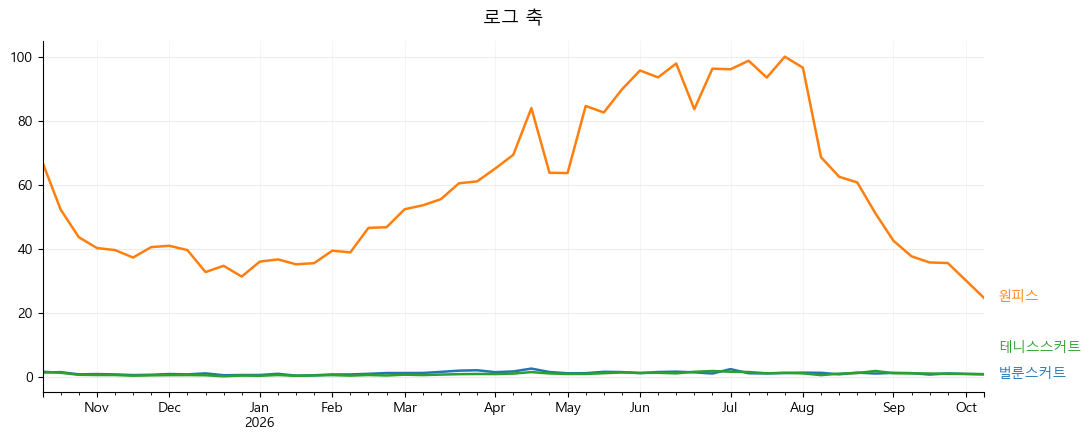

In [ ]:
df, ax = plot_trend(["원피스", "벌룬스커트", "테니스스커트"],
                    weeks=52, logy=True, title="로그 축")

세로 눈금이 `10⁻²` 가 아니라 `0.01` 로 나오게 해뒀다.
한글 폰트에는 수학용 음수기호(U+2212)가 없어서 그대로 두면 깨지는 자리다.

선이 뚝뚝 끊긴 구간은 **네이버가 데이터를 보내지 않은 주**다 (7번의 `NaN`).

### 저장하기

`ax` 를 받았으니 그대로 파일로 떨굴 수 있다.

In [ ]:
df, ax = plot_trend(["가디건", "니트"], weeks=26, gender="f", ages=["10", "20"])
ax.figure.savefig("data/raw/추이.png", dpi=150, bbox_inches="tight")

### 그림 여러 개를 한 장에

`ax` 를 넘기면 원하는 자리에 그려준다.

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
plot_trend(["가디건", "니트"], weeks=52, ax=axes[0], title="상의")
plot_trend(["코트", "패딩"], weeks=52, ax=axes[1], title="아우터")
fig.tight_layout()

두 그림은 **서로 다른 요청**에서 왔으므로 세로 눈금을 직접 비교하면 안 된다 (6번 참고).
모양만 비교할 것.

---
## 인자 정리

```python
get_trend(
    keywords,              # 리스트. 5개 초과하면 자동 분할
    weeks=52,              # 최근 N주
    start=None, end=None,  # "2026-01-01" 형식. 주면 weeks 를 무시
    time_unit="week",      # "date" | "week" | "month"
    category="50000000",   # 패션의류
    gender=None,           # "m" | "f"
    ages=None,             # ["10","20"] 처럼
    env_path=".env",
)
```

`plot_trend` 는 위 인자를 그대로 받고 다음이 더 있다.

```python
plot_trend(
    ...,                   # get_trend 와 동일
    logy=False,            # 세로축 로그
    title=None,            # 없으면 세그먼트 보고 자동
    figsize=(11, 4.5),
    ax=None,               # 기존 축에 그리기
)                          # → (df, ax) 를 돌려준다
```

### 기억할 것 세 가지

1. `ratio` 는 **한 요청 안의** 상대값이다. 요청이 다르면 비교하지 않는다
2. 키워드는 **5개 이하**로 끊어 쓴다
3. `NaN` 은 네이버가 안 보낸 구간이다. 0이 아니다

In [14]:
get_trend(["블라우스"],category="50000000",gender="f")

,period,keyword,ratio,batch
0,2025-10-13,블라우스,68.82668,1
1,2025-10-20,블라우스,47.76652,1
2,2025-10-27,블라우스,32.32876,1
3,2025-11-03,블라우스,26.95652,1
4,2025-11-10,블라우스,27.45681,1
5,2025-11-17,블라우스,22.68016,1
6,2025-11-24,블라우스,24.95533,1
7,2025-12-01,블라우스,27.75461,1
8,2025-12-08,블라우스,22.28707,1
9,2025-12-15,블라우스,20.78618,1
